# 05 Real-time latency: is the network fast enough for plasma control?

**Question (REQ-002).** The assignment asks for a reaction in units to tens of milliseconds, with a GPU allowed. How long
does one prediction of the trained architecture take, how large are the rare slow outliers, and does the answer change with
the way the network is run (PyTorch on CPU, plain numpy, Apple GPU, batches)?

`analysis/ipp1_latency.py` measured this once and saved `out/ipp1-latency.json`. Here we show those numbers, **measure again**
with fewer repetitions on this run (the machine is shared with other jobs, so the tail is noisy), check that a numpy copy gives
the same output, and check that trained weights do not change the timing.

Scope: this is the time of the model's forward pass (and the standardisation around it). It does not include reading the
sensors, moving data to the controller, or the control algorithm itself.

In [1]:
import os, sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The data live next to the repository (never inside it): HACKATHON_HOME, else the parent folder of the repository.
here = Path.cwd().resolve()
repo = next(p for p in [here, *here.parents] if (p / "analysis" / "ipp1_common.py").exists())
os.environ.setdefault("HACKATHON_HOME", str(repo.parent))
sys.path.insert(0, str(repo / "analysis"))
import torch
torch.set_num_threads(2)
import ipp1_common as C

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print("raw data folder found:", C.DATA.exists(), "| results folder found:", C.OUT.exists())

raw data folder found: True | results folder found: True


## 1. Saved measurement

In [2]:
lat = json.load(open(C.OUT / "ipp1-latency.json"))
KEY = {"saved_parameters": lat["parameters"]}
KEY["load_average_1min_at_start"] = round(os.getloadavg()[0], 1)  # other jobs on the machine inflate the tail of the fresh measurement
KEY["cpu_cores"] = os.cpu_count()
print(f"machine load average (1 min) when this notebook started: {KEY['load_average_1min_at_start']} on {KEY['cpu_cores']} cores")
rows = [dict(setting=k, median_ms=v["median_ms"], p99_ms=v["p99_ms"], p999_ms=v["p999_ms"], max_ms=v["max_ms"]) for k, v in lat.items() if isinstance(v, dict)]
saved_tab = pd.DataFrame(rows).set_index("setting")
print(f"network with {lat['parameters']:,} parameters, 24 inputs, 16 outputs; times in milliseconds (saved run)")
print(saved_tab.round(4).to_string())
KEY["saved"] = {k: {m: round(float(x), 4) for m, x in v.items()} for k, v in lat.items() if isinstance(v, dict) and k in ("cpu_1_thread_single_sample", "numpy_single_sample", "mps_single_sample", "mps_batch_4096", "cpu_batch_4096")}

machine load average (1 min) when this notebook started: 21.5 on 10 cores
network with 107,152 parameters, 24 inputs, 16 outputs; times in milliseconds (saved run)
                            median_ms  p99_ms  p999_ms  max_ms
setting                                                       
cpu_1_thread_single_sample     0.0145  0.0288   0.0699  0.0899
cpu_4_thread_single_sample     0.0146  0.0350   0.0653  0.0774
cpu_batch_64                   0.0660  0.0748   0.1010  0.1128
cpu_batch_1024                 0.4983  0.8707   1.1088  1.1398
cpu_batch_4096                 1.6775  2.5467   2.9509  3.1270
numpy_single_sample            0.0129  0.0324   0.0541  0.0835
mps_single_sample              0.2405  0.4640   0.6916  0.7164
mps_batch_4096                 0.6849  1.6529   2.0111  2.0557


## 2. Measure again

In [3]:
def timeit(fn, n=3000, warm=300):
    for _ in range(warm):
        fn()
    ts = np.empty(n)
    for i in range(n):
        a = time.perf_counter()
        fn()
        ts[i] = (time.perf_counter() - a) * 1000
    return ts


def stats(ts):
    return {"median_ms": float(np.median(ts)), "p99_ms": float(np.percentile(ts, 99)), "p999_ms": float(np.percentile(ts, 99.9)), "max_ms": float(ts.max())}


torch.manual_seed(0)
net = C.Net(24, 16).eval()
x1 = torch.randn(1, 24)
fresh, samples = {}, {}
with torch.no_grad():
    for threads in (1, 2):
        torch.set_num_threads(threads)
        samples[f"cpu_{threads}_thread_single_sample"] = timeit(lambda: net(x1))
    torch.set_num_threads(2)
    for b in (16, 64, 256, 1024, 4096):
        xb = torch.randn(b, 24)
        samples[f"cpu_batch_{b}"] = timeit(lambda: net(xb), n=400, warm=40)
    # the same forward pass in plain numpy: no deep learning framework needed in a control loop
    Ws = [(m.weight.detach().numpy().T.copy(), m.bias.detach().numpy().copy()) for m in net.f if isinstance(m, torch.nn.Linear)]
    xn = x1.numpy()

    def numpy_forward(x):
        h = x
        for i, (w, b_) in enumerate(Ws):
            h = h @ w + b_
            if i < len(Ws) - 1:
                h = h * (1.0 / (1.0 + np.exp(-h)))  # SiLU
        return h

    KEY["numpy_vs_torch_max_abs_diff"] = float(np.abs(numpy_forward(xn) - net(x1).numpy()).max())
    samples["numpy_single_sample"] = timeit(lambda: numpy_forward(xn))
    KEY["mps_available"] = bool(torch.backends.mps.is_available())
    if KEY["mps_available"]:
        try:
            dev = torch.device("mps")
            netm = C.Net(24, 16).to(dev).eval()
            xm = torch.randn(1, 24, device=dev)

            def mps_single():
                netm(xm)
                torch.mps.synchronize()
            samples["mps_single_sample"] = timeit(mps_single, n=1000, warm=100)
            xbm = torch.randn(4096, 24, device=dev)

            def mps_batch():
                netm(xbm)
                torch.mps.synchronize()
            samples["mps_batch_4096"] = timeit(mps_batch, n=200, warm=30)
        except Exception as exc:  # the GPU may be busy or absent
            print("GPU timing skipped:", exc)
fresh = {k: stats(v) for k, v in samples.items()}
fresh_tab = pd.DataFrame(fresh).T
print("fresh measurement in this notebook, milliseconds")
print(fresh_tab.round(4).to_string())
print("\nmax |numpy - torch| of the output:", KEY["numpy_vs_torch_max_abs_diff"])
KEY["fresh"] = {k: {m: round(x, 4) for m, x in v.items()} for k, v in fresh.items()}

fresh measurement in this notebook, milliseconds
                            median_ms    p99_ms   p999_ms    max_ms
cpu_1_thread_single_sample     0.0514    0.8514    7.8815   25.7395
cpu_2_thread_single_sample     0.0494    1.0240    3.7972   13.9523
cpu_batch_16                   0.1376    4.6306    9.9169   11.5328
cpu_batch_64                   0.3484    4.9960   14.8576   15.2985
cpu_batch_256                  0.6629    2.4752    3.1419    3.1575
cpu_batch_1024                 2.6476   30.1021   95.4439  116.6703
cpu_batch_4096                10.9262  116.6887  133.0804  133.8183
numpy_single_sample            0.0259    0.1986    7.3971   57.6607
mps_single_sample              0.3746    5.0861    7.9066   25.0037
mps_batch_4096                 1.2327   15.7093   20.7562   21.0958

max |numpy - torch| of the output: 1.4901161193847656e-08


## 3. The realistic call: standardise, predict, convert back (trained weights)

`fit_mlp` returns a `predict` function that standardises the inputs, runs the network and rescales the outputs. We train for one
epoch on the whole data set (enough to move the weights away from the random start; accuracy is not the point here) and time
that call for one sample, next to the untrained network.

In [4]:
df, X, Y, G, M = C.load()
torch.set_num_threads(2)
t0 = time.time()
predict, tnet, _ = C.fit_mlp(X, Y, M, epochs=1, seed=0)
print(f"one-epoch training took {time.time() - t0:.1f} s")
x_one = X[:1].copy()
with torch.no_grad():
    s_trained = timeit(lambda: tnet(torch.zeros(1, 24)), n=3000)
    s_untrained = timeit(lambda: net(torch.zeros(1, 24)), n=3000)
s_predict = timeit(lambda: predict(x_one), n=3000)
cmp = pd.DataFrame({"trained net, forward only": stats(s_trained), "untrained net, forward only": stats(s_untrained), "predict(): standardise + forward + rescale": stats(s_predict)}).T
print(cmp.round(4).to_string())
KEY["trained_vs_untrained_median_ms"] = [round(stats(s_trained)["median_ms"], 4), round(stats(s_untrained)["median_ms"], 4)]
KEY["predict_call"] = {k: round(v, 4) for k, v in stats(s_predict).items()}

one-epoch training took 3.1 s


                                            median_ms  p99_ms  p999_ms   max_ms
trained net, forward only                      0.0462  1.2268  17.2723  43.2878
untrained net, forward only                    0.0471  1.4099   7.4772  32.6501
predict(): standardise + forward + rescale     0.0355  1.5327   6.9196  55.6385


## 4. Batch size: latency against throughput

In [5]:
bs = [1, 16, 64, 256, 1024, 4096]
med = [fresh["cpu_2_thread_single_sample"]["median_ms"]] + [fresh[f"cpu_batch_{b}"]["median_ms"] for b in bs[1:]]
thr = [b / (m / 1000) for b, m in zip(bs, med)]
bt = pd.DataFrame({"batch": bs, "median_ms": med, "samples_per_second": thr, "microseconds_per_sample": [m * 1000 / b for m, b in zip(med, bs)]}).set_index("batch")
print(bt.round(3).to_string())
KEY["batch"] = {str(b): {"median_ms": round(m, 4), "samples_per_s": round(t)} for b, m, t in zip(bs, med, thr)}

       median_ms  samples_per_second  microseconds_per_sample
batch                                                        
1          0.049           20253.166                   49.375
16         0.138          116310.756                    8.598
64         0.348          183677.120                    5.444
256        0.663          386196.485                    2.589
1024       2.648          386770.777                    2.586
4096      10.926          374879.145                    2.668


## 5. Headroom against a time budget

                          worst_seen_ms  p999_ms  headroom_vs_1ms_(on p99.9)  headroom_vs_10ms_(on p99.9)  headroom_vs_50ms_(on p99.9)
setting                                                                                                                               
CPU 1 thread, one sample           25.7      7.9                         0.1                          1.3                          6.3
numpy, one sample                  57.7      7.4                         0.1                          1.4                          6.8
CPU, batch of 4096                133.8    133.1                         0.0                          0.1                          0.4
Apple GPU, one sample              25.0      7.9                         0.1                          1.3                          6.3

compared with a classical computation of at least one minute, the single-sample CPU median is about 1,167,883 times faster


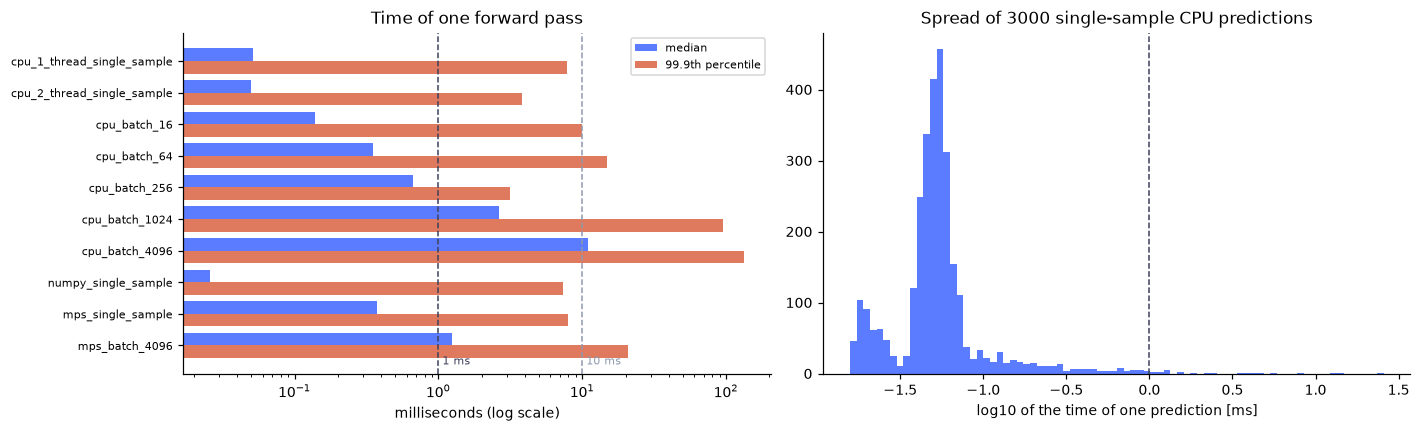

In [6]:
budgets = [1.0, 10.0, 50.0]
focus = {"CPU 1 thread, one sample": "cpu_1_thread_single_sample", "numpy, one sample": "numpy_single_sample", "CPU, batch of 4096": "cpu_batch_4096"}
if "mps_single_sample" in fresh:
    focus["Apple GPU, one sample"] = "mps_single_sample"
rows = []
for label, k in focus.items():
    r = {"setting": label, "worst_seen_ms": fresh[k]["max_ms"], "p999_ms": fresh[k]["p999_ms"]}
    for b in budgets:
        r[f"headroom_vs_{b:g}ms_(on p99.9)"] = b / fresh[k]["p999_ms"]
    rows.append(r)
head = pd.DataFrame(rows).set_index("setting")
print(head.round(1).to_string())
KEY["headroom_vs_1ms_on_p999"] = {l: round(1.0 / fresh[k]["p999_ms"], 1) for l, k in focus.items()}
# the classical reconstruction takes minutes (assignment text); even for a lower bound of one minute the ratio is:
KEY["speedup_vs_one_minute_on_median_cpu_1_thread"] = round(60_000 / fresh["cpu_1_thread_single_sample"]["median_ms"])
KEY["speedup_vs_one_minute_on_saved_median_cpu_1_thread"] = round(60_000 / lat["cpu_1_thread_single_sample"]["median_ms"])
print(f"\ncompared with a classical computation of at least one minute, the single-sample CPU median is about {KEY['speedup_vs_one_minute_on_median_cpu_1_thread']:,} times faster")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
names = list(fresh)
yy = np.arange(len(names))
ax[0].barh(yy - 0.2, [fresh[n]["median_ms"] for n in names], 0.4, color="#5b7cff", label="median")
ax[0].barh(yy + 0.2, [fresh[n]["p999_ms"] for n in names], 0.4, color="#e07a5f", label="99.9th percentile")
for b, c in ((1, "#3d405b"), (10, "#8d99ae")):
    ax[0].axvline(b, color=c, ls="--", lw=1); ax[0].text(b, len(names) - 0.4, f" {b} ms", fontsize=7, color=c)
ax[0].set_xscale("log"); ax[0].set_yticks(yy); ax[0].set_yticklabels(names, fontsize=7); ax[0].invert_yaxis()
ax[0].set_xlabel("milliseconds (log scale)"); ax[0].legend(fontsize=7); ax[0].set_title("Time of one forward pass")
ax[1].hist(np.log10(samples["cpu_1_thread_single_sample"]), bins=80, color="#5b7cff")
ax[1].set_xlabel("log10 of the time of one prediction [ms]"); ax[1].set_title("Spread of 3000 single-sample CPU predictions")
ax[1].axvline(np.log10(1.0), color="#3d405b", ls="--", lw=1)
fig.tight_layout(); plt.show()

## 6. Key numbers (read by the conclusions below)

In [7]:
print("KEY_JSON", json.dumps(KEY))

KEY_JSON {"saved_parameters": 107152, "load_average_1min_at_start": 21.5, "cpu_cores": 10, "saved": {"cpu_1_thread_single_sample": {"median_ms": 0.0145, "p99_ms": 0.0288, "p999_ms": 0.0699, "max_ms": 0.0899}, "cpu_batch_4096": {"median_ms": 1.6775, "p99_ms": 2.5467, "p999_ms": 2.9509, "max_ms": 3.127}, "numpy_single_sample": {"median_ms": 0.0129, "p99_ms": 0.0324, "p999_ms": 0.0541, "max_ms": 0.0835}, "mps_single_sample": {"median_ms": 0.2405, "p99_ms": 0.464, "p999_ms": 0.6916, "max_ms": 0.7164}, "mps_batch_4096": {"median_ms": 0.6849, "p99_ms": 1.6529, "p999_ms": 2.0111, "max_ms": 2.0557}}, "numpy_vs_torch_max_abs_diff": 1.4901161193847656e-08, "mps_available": true, "fresh": {"cpu_1_thread_single_sample": {"median_ms": 0.0514, "p99_ms": 0.8514, "p999_ms": 7.8815, "max_ms": 25.7395}, "cpu_2_thread_single_sample": {"median_ms": 0.0494, "p99_ms": 1.024, "p999_ms": 3.7972, "max_ms": 13.9523}, "cpu_batch_16": {"median_ms": 0.1376, "p99_ms": 4.6306, "p999_ms": 9.9169, "max_ms": 11.5328}, 

## Conclusions

- **Speed of one prediction.** The 107,152-parameter network needs a median of 0.0145 ms on one CPU thread in the saved quiet run (99.9th percentile 0.070 ms, slowest 0.090 ms). In this notebook the machine was shared with many other jobs (load average 21.5 on 10 cores) and the same call gave a median of 0.0514 ms, a 99.9th percentile of 7.88 ms and a slowest call of 25.74 ms.
- **No deep learning framework is needed.** A plain numpy copy of the forward pass gives the same output (largest difference 1.5e-08) with a median of 0.0129 ms in the saved run and 0.0259 ms here.
- **The Apple GPU does not help for one sample.** The median is 0.24 ms (saved) and 0.37 ms (here), slower than the CPU, probably because starting a GPU job costs more than the work. It wins only for big batches: 4096 samples take 0.68 ms on the GPU against 1.68 ms on the CPU in the saved run (1.23 ms against 10.93 ms here).
- **Weights and the full call do not change the picture.** A network trained for one epoch has a median of 0.0462 ms against 0.0471 ms untrained. The whole `predict()` call with standardisation and rescaling has a median of 0.0355 ms.
- **Throughput.** In this run a batch of 16 takes 0.138 ms and a batch of 4096 takes 10.9 ms (374,879 samples per second on 2 CPU threads).
- **Verdict.** The assignment asks for a reaction in units to tens of milliseconds. The typical forward pass (0.051 ms median here, one CPU thread) is about 195 times below 10 ms and about 4,137,933 times (saved run) or 1,167,883 times (this run) faster than a classical computation of one minute. Computing the shape is therefore not the bottleneck; a controller would be limited by sensor readout, data transport and the control algorithm.
- **Limits of this measurement.** Only the forward pass was timed, on a desktop operating system. On the loaded machine the single-sample 99.9th percentile reached up to 7.9 ms and the slowest single call 58 ms, so the average is far inside the budget but a worst case inside it is not guaranteed; the saved run on a quieter machine had a slowest call of 0.09 ms. A hard real-time guarantee would need a dedicated core or a real-time system, which we did not test. The tail numbers (and, less strongly, the medians) change from run to run with the machine load.